# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [34]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136084"
NAME = "윤성민"
HF_USER = "SEONGMIN1234"

TASK = "Grab the black cube."   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/so101-pick-cube-2cam-50ep_20261112_132007"   # 세 정책이 공통으로 사용한 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)
CHUNK_SIZES = [10, 50, 100]

# 정책 repo (과제 2 정책을 재사용하면 100번 항목을 과제 2 repo로 바꿀 것)
POLICY_REPOS = {k: f"{HF_USER}/act_pick_cube_chunk{k}" for k in CHUNK_SIZES}

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 조건별로 그대로 적을 것 (과제 2 평가를 재사용하면 100번 항목에 과제 2 평가 데이터셋을 적는다)
EVAL_DATASETS = {
    10:  f"{HF_USER}/rollout_act_pick-cube_chunk10",
    50:  f"{HF_USER}/rollout_act_pick-cube_chunk50",
    100: f"{HF_USER}/rollout_act_pick-cube_chunk100",
}
WANDB_URL = "https://forge.coreweave.com/wandb/seougmin1234-study-com/so101-act-chunk/workspace?nw=nwuserseougmin1234"   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
for k in CHUNK_SIZES:
    print(f"chunk{k:<4} 정책 :", f"https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk{k:<4} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136084 윤성민
태스크        : Grab the black cube.
학습 데이터셋 : https://huggingface.co/datasets/SEONGMIN1234/so101-pick-cube-2cam-50ep_20261112_132007
chunk10   정책 : https://huggingface.co/SEONGMIN1234/act_pick_cube_chunk10
chunk10   평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_act_pick-cube_chunk10
chunk50   정책 : https://huggingface.co/SEONGMIN1234/act_pick_cube_chunk50
chunk50   평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_act_pick-cube_chunk50
chunk100  정책 : https://huggingface.co/SEONGMIN1234/act_pick_cube_chunk100
chunk100  평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_act_pick-cube_chunk100
wandb         : https://forge.coreweave.com/wandb/seougmin1234-study-com/so101-act-chunk/workspace?nw=nwuserseougmin1234


In [35]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [36]:
# Hub 접근 확인 — 7개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] SEONGMIN1234/so101-pick-cube-2cam-50ep_20261112_132007  (파일 10개)
OK   [model  ] SEONGMIN1234/act_pick_cube_chunk10  (파일 8개)
OK   [model  ] SEONGMIN1234/act_pick_cube_chunk50  (파일 8개)
OK   [model  ] SEONGMIN1234/act_pick_cube_chunk100  (파일 9개)
OK   [dataset] SEONGMIN1234/rollout_act_pick-cube_chunk10  (파일 17개)
OK   [dataset] SEONGMIN1234/rollout_act_pick-cube_chunk50  (파일 8개)
OK   [dataset] SEONGMIN1234/rollout_act_pick-cube_chunk100  (파일 8개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [37]:
# 학습 데이터셋의 fps와 에피소드 길이로 청크 길이 환산
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for k in CHUNK_SIZES:
        print(f"chunk_size={k:>3d} -> {k/fps:5.2f} s  (평균 에피소드의 {k/fps/ep_len_s*100:4.1f}%)")

fps: 15, 에피소드 수: 50, 평균 에피소드 길이: 17.4 s

chunk_size= 10 ->  0.67 s  (평균 에피소드의  3.8%)
chunk_size= 50 ->  3.33 s  (평균 에피소드의 19.2%)
chunk_size=100 ->  6.67 s  (평균 에피소드의 38.4%)


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건과 이유: Chunk 50, 10일때는 너무 중간의 경로를 계속 바꾸고, 100일때는 중간에 움직여도 이미 생성된 행동으로 진행하여 그 사이인 50일때가 성공률이 가장 높을 것 같다.
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유: chunk 100, 100만큼의 행동을 예상하여서 다른 두 경우보다 많은 행동을 생성하여 한번에 움직이기 때문
- 물체가 중간에 움직였을 때 가장 잘 따라갈 것으로 예상하는 조건과 이유: chunk 10일때, 10만큼의 청크를 생성하여서 중간에 움직여서 바로 반응하여서

### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [38]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    same = cfg_df[col].nunique(dropna=False) == 1
    print(("[일치]   " if same else "[불일치] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치]   " if ok else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,SEONGMIN1234/so101-pick-cube-2cam-50ep,100000,4,1000
chunk50,50,50,10.0,SEONGMIN1234/so101-pick-cube-2cam-50ep,100000,4,1000
chunk100,100,100,10.0,SEONGMIN1234/so101-pick-cube-2cam-50ep,100000,4,1000


[일치]   kl_weight
[일치]   dataset
[일치]   steps
[일치]   batch_size
[일치]   seed
[일치]   chunk10: chunk_size=10, n_action_steps=10
[일치]   chunk50: chunk_size=50, n_action_steps=50
[일치]   chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 3개를 아래 코드 블록에 붙여 넣는다. 과제 2 정책을 재사용했다면 chunk100 자리에 "과제 2 정책 재사용"과 repo_id를 적는다.

```bash
# chunk_size = 10
lerobot-train \
  --dataset.repo_id=SEONGMIN1234/so101-pick-cube-2cam-50ep \
  --dataset.root=/home/work/lerobot/datasets/so101-pick-cube-2cam-50ep \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=10 \
  --policy.n_action_steps=10 \
  --policy.device=cuda \
  --policy.repo_id=SEONGMIN1234/act_pick_cube_chunk10 \
  --policy.push_to_hub=true \
  --policy.private=false \
  --output_dir=/home/work/lerobot/outputs/act_chunk10_100k_v3 \
  --job_name=act_chunk10_100k_v3 \
  --batch_size=4 \
  --steps=100000 \
  --seed=1000 \
  --save_freq=5000 \
  --log_freq=100 \
  --wandb.enable=true \
  --wandb.project=so101-act-chunk

# chunk_size = 50
lerobot-train \
  --dataset.repo_id=SEONGMIN1234/so101-pick-cube-2cam-50ep \
  --dataset.root=/home/work/lerobot/datasets/so101-pick-cube-2cam-50ep \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=50 \
  --policy.n_action_steps=50 \
  --policy.device=cuda \
  --policy.repo_id=SEONGMIN1234/act_pick_cube_chunk50 \
  --policy.push_to_hub=true \
  --policy.private=false \
  --output_dir=/home/work/lerobot/outputs/act_chunk50_100k \
  --job_name=act_chunk50_100k \
  --batch_size=4 \
  --steps=100000 \
  --seed=1000 \
  --save_freq=5000 \
  --log_freq=100 \
  --wandb.enable=true \
  --wandb.project=so101-act-chunk

# chunk_size = 100
lerobot-train \
  --dataset.repo_id=SEONGMIN1234/so101-pick-cube-2cam-50ep \
  --dataset.root=/home/work/lerobot/datasets/so101-pick-cube-2cam-50ep \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=100 \
  --policy.n_action_steps=100 \
  --policy.device=cuda \
  --policy.repo_id=SEONGMIN1234/act_pick_cube_chunk100 \
  --policy.push_to_hub=true \
  --policy.private=false \
  --output_dir=/home/work/lerobot/outputs/act_chunk100_100k \
  --job_name=act_chunk100_100k \
  --batch_size=4 \
  --steps=100000 \
  --seed=1000 \
  --save_freq=5000 \
  --log_freq=100 \
  --wandb.enable=true \
  --wandb.project=so101-act-chunk
```

> 참고 (0.6.0): `--policy.repo_id`를 주면 학습 후 정책이 Hub에 자동 업로드된다. 학습 기본값은 `steps=100000`, `batch_size=8`, `seed=1000`이다. 세 조건을 같은 값으로 맞추려면 기본값을 쓰더라도 명령어에 명시해 두는 편이 안전하다.

### 2-2. 학습 환경
`[작성]`
- GPU: NVIDIA H200 (Backend.AI, 0.5 fGPU 할당)
- 학습 step 수 (세 조건 공통): 100,000
- 조건별 소요 시간 (chunk10 / chunk50 / chunk100): 3시간, 2시간 30분, 3시간 30분

### 2-3. 학습 곡선
`[작성]` 세 조건의 loss 곡선을 **한 그래프에 겹쳐** 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw3.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw3.png)

In [39]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 나머지 열이 조건별 loss (열 이름은 본인 파일에 맞게 수정)
import os
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_hw3.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    for col in df.columns[1:]:
        plt.plot(df.iloc[:, 0], df[col], label=col)
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss by chunk_size")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [40]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# ACT는 l1_loss(행동 복원 손실)와 kld_loss(KL 항)를 따로 출력한다
final_loss = pd.DataFrame({
    "chunk_size": CHUNK_SIZES,
    "l1_loss":  [0.054342, 0.055613, 0.071494],
    "kld_loss": [0.00006, 0.00011, 0.00015],
}).set_index("chunk_size")
final_loss

,l1_loss,kld_loss
chunk_size,,
10,0.054342,0.00006
50,0.055613,0.00011
100,0.071494,0.00015


## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜
1. 테이블에 물체 시작 위치 10곳을 테이프로 표시하고 1~10번을 매긴다. **세 정책 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준을 **평가 전에** 아래에 적고, 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 물체를 집고 해당 바구니에 물체 넣기
- 실패: 물체를 집기만 하고 바구니에 물체를 못 넣는 경우
- 에피소드 제한 시간(초): 60

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어 3개를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
# chunk_size = 10
python rollout_with_2cameras.py \
  --strategy.type=episodic \
  --strategy.reset_to_initial_position=false \
  --policy.path=SEONGMIN1234/act_pick_cube_chunk10 \
  --device=cpu \
  --fps=15 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM1 \
  --robot.id=follower1 \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM0 \
  --teleop.id=leader1 \
  --dataset.repo_id=SEONGMIN1234/rollout_act_pick-cube_chunk10 \
  --dataset.root="$HOME/so_arm_ws/datasets/rollout_act_pick-cube_chunk10" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.fps=15 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=60 \
  --dataset.push_to_hub=false \
  --return_to_initial_position=false \
  --display_data=false \
  --play_sounds=false

# chunk_size = 50
python rollout_with_2cameras.py \
  --strategy.type=episodic \
  --strategy.reset_to_initial_position=false \
  --policy.path=SEONGMIN1234/act_pick_cube_chunk50 \
  --device=cpu \
  --fps=15 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM1 \
  --robot.id=follower1 \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM0 \
  --teleop.id=leader1 \
  --dataset.repo_id=SEONGMIN1234/rollout_act_pick-cube_chunk50 \
  --dataset.root="$HOME/so_arm_ws/datasets/rollout_act_pick-cube_chunk50" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.fps=15 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=60 \
  --dataset.push_to_hub=false \
  --return_to_initial_position=false \
  --display_data=false \
  --play_sounds=false

# chunk_size = 100
python rollout_with_2cameras.py \
  --strategy.type=episodic \
  --strategy.reset_to_initial_position=false \
  --policy.path=SEONGMIN1234/act_pick_cube_chunk100 \
  --device=cpu \
  --fps=15 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM1 \
  --robot.id=follower1 \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM0 \
  --teleop.id=leader1 \
  --dataset.repo_id=SEONGMIN1234/rollout_act_pick-cube_chunk100 \
  --dataset.root="$HOME/so_arm_ws/datasets/rollout_act_pick-cube_chunk100" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.fps=15 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=60 \
  --dataset.push_to_hub=false \
  --return_to_initial_position=false \
  --display_data=false \
  --play_sounds=false
```

In [41]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CHUNK_SIZES:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"chunk{k:<4} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f"chunk {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

chunk10   에피소드 10개, 프레임 4661, fps 15  -> 통과
chunk50   에피소드 10개, 프레임 6302, fps 15  -> 통과
chunk100  에피소드 10개, 프레임 6780, fps 15  -> 통과
chunk 10 이름 규칙: 통과
chunk 50 이름 규칙: 통과
chunk 100 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. (예: "큐브 위치를 놓침", "청크가 바뀌는 순간 팔이 튐", "목표 근처에서 계속 떨림")

In [42]:
def blank(): 
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

results = {
    10: [
        {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "큐브 집기 후 바구니에 넣지 못함"},
        {"episode": 1, "position": 2, "success": True, "smooth": 4, "note": ""},
        {"episode": 2, "position": 3, "success": False, "smooth": 2, "note": "큐브 집기 후 바구니에 넣지 못함"},
        {"episode": 3, "position": 4, "success": False, "smooth": 2, "note": "큐브 집기 후 바구니에 넣지 못함"},
        {"episode": 4, "position": 5, "success": True, "smooth": 4, "note": ""},
        {"episode": 5, "position": 6, "success": False, "smooth": 1, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 6, "position": 7, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 7, "position": 8, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 8, "position": 9, "success": False, "smooth": 2, "note": "큐브 집기 후 바구니에 넣지 못함"},
        {"episode": 9, "position": 10, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
    ],
    50: [
        {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 1, "position": 2, "success": False, "smooth": None, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 2, "position": 3, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 3, "position": 4, "success": False, "smooth": 2, "note": "바구니에 큐브를 집지 않은 상태로 넣음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 5, "position": 6, "success": True, "smooth": 4, "note": ""},
        {"episode": 6, "position": 7, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 7, "position": 8, "success": True, "smooth": 4, "note": ""},
        {"episode": 8, "position": 9, "success": True, "smooth": 4, "note": ""},
        {"episode": 9, "position": 10, "success": True, "smooth": 5, "note": ""},
    ],
    100: [
        {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "바구니에 큐브를 놓지 못함"},
        {"episode": 1, "position": 2, "success": False, "smooth": 2, "note": "바구니를 건들려서 계속 위치가 옮겨짐"},
        {"episode": 2, "position": 3, "success": False, "smooth": 2, "note": "바구니를 건들려서 계속 위치가 옮겨짐"},
        {"episode": 3, "position": 4, "success": False, "smooth": 1, "note": "바구니를 건들려서 계속 위치가 옮겨짐"},
        {"episode": 4, "position": 5, "success": False, "smooth": 2, "note": "바구니를 건들려서 계속 위치가 옮겨짐"},
        {"episode": 5, "position": 6, "success": True, "smooth": 4, "note": ""},
        {"episode": 6, "position": 7, "success": True, "smooth": 4, "note": ""},
        {"episode": 7, "position": 8, "success": True, "smooth": 4, "note": ""},
        {"episode": 8, "position": 9, "success": False, "smooth": 3, "note": "큐브를 잡지 못함"},
        {"episode": 9, "position": 10, "success": False, "smooth": 3, "note": "큐브를 잡고 바구니가 아닌 그 옆에 둠"},
    ],
}
# 예시: results[10][0] = {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "파지 직전 좌우로 떨리다 놓침"}

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("chunk_size")
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary

,success_rate,mean_smooth
chunk_size,,
10,20.0,2.3
50,40.0,3.0
100,30.0,2.7


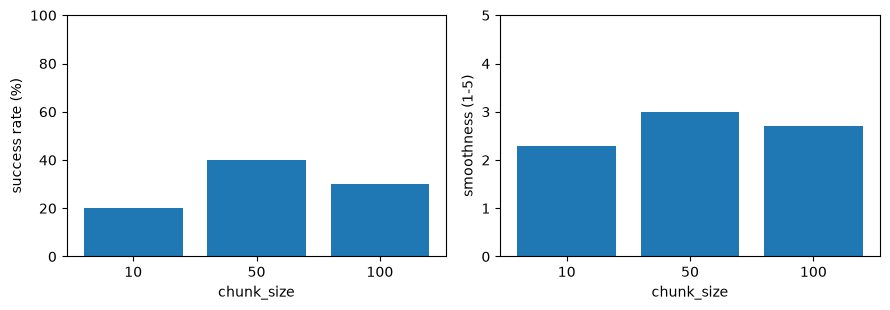

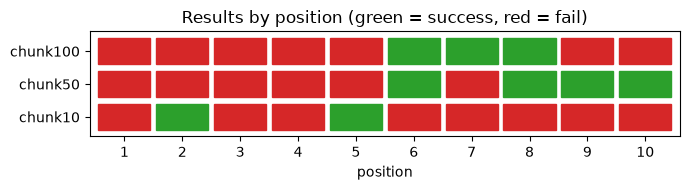

In [43]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
labels = [str(k) for k in summary.index]
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_xlabel("chunk_size"); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = chunk_size, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CHUNK_SIZES):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CHUNK_SIZES) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CHUNK_SIZES)))
ax.set_yticklabels([f"chunk{k}" for k in CHUNK_SIZES]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
조건별로 3회씩 추가로 시도하되, 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮긴다.** 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음)

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다.

`[작성]` 아래 `reactivity`를 채운다.

In [44]:
import pandas as pd

reactivity = {
    10: [
        {"trial": 0, "followed": True,  "note": "큐브 위치 변경에 반응하여 경로 수정 성공"},
        {"trial": 1, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
        {"trial": 2, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
    ],
    50: [
        {"trial": 0, "followed": True,  "note": "큐브 위치 변경에 반응하여 경로 수정 성공"},
        {"trial": 1, "followed": True,  "note": "큐브 위치 변경에 반응하여 경로 수정 성공"},
        {"trial": 2, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
    ],
    100: [
        {"trial": 0, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
        {"trial": 1, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
        {"trial": 2, "followed": False, "note": "큐브 위치 변경에 반응하지 못함"},
    ],
}
react_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("chunk_size")["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3"))
react_df

chunk_size
10     1/3
50     2/3
100    0/3
Name: followed, dtype: object


,trial,followed,note,chunk_size
0,0,True,큐브 위치 변경에 반응하여 경로 수정 성공,10
1,1,False,큐브 위치 변경에 반응하지 못함,10
2,2,False,큐브 위치 변경에 반응하지 못함,10
3,0,True,큐브 위치 변경에 반응하여 경로 수정 성공,50
4,1,True,큐브 위치 변경에 반응하여 경로 수정 성공,50
5,2,False,큐브 위치 변경에 반응하지 못함,50
6,0,False,큐브 위치 변경에 반응하지 못함,100
7,1,False,큐브 위치 변경에 반응하지 못함,100
8,2,False,큐브 위치 변경에 반응하지 못함,100


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
chunk_size에 따른 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: chunk10의 떨림, chunk100의 청크 경계 튐)

![chunk10](images/hw3_chunk10.gif)
![chunk50](images/hw3_chunk50.gif)
![chunk100](images/hw3_chunk100.gif)

## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

**4-2. 짧은 청크의 문제** — chunk_size=10에서 관찰된 동작의 특징(떨림, 머뭇거림, 경로 이탈 등)을 compounding error 개념으로 설명하라. Compounding Error(누적 오차)는 작은 행동 예측 오차가 반복되면서 로봇의 실제 상태가 학습 데이터에서 경험한 상태와 점차 달라지고, 이러한 차이가 이후 행동 예측에도 영향을 미치는 현상이다.

실제 Chunk 10 평가에서는 큐브를 집는 데 성공했지만 이후 상승과 바구니 이동 작업을 완료하지 못하였다. 다만 눈에 띄는 떨림이나 경로 이탈이 직접 확인된 것은 아니므로, 이를 누적 오차에 의한 현상이라고 단정할 수는 없다.

**4-3. 긴 청크의 대가** — chunk_size=100에서 청크가 바뀌는 순간 동작이 끊기거나 튀는 현상이 있었는가? 반응성 테스트 결과와 함께 설명하라. Chunk 100 모델은 한 번의 추론으로 100개의 미래 행동을 예측한다. 따라서 Chunk 10보다 새로운 관측을 반영하는 빈도가 낮으며, 한 번 예측한 행동이 실제 환경과 달라졌을 때 수정하기 어렵다.

실제 평가에서는 Chunk 100 모델이 큐브를 제대로 집지 못한 사례와 큐브를 집었지만 이후 상승 및 배치 동작을 수행하지 못한 사례가 관찰되었다. 이러한 결과는 긴 행동 청크가 환경 변화에 대응하는 데 불리할 가능성을 보여준다.

**4-4. 오프라인 손실과 실제 성능** — 2-3의 `l1_loss`가 낮은 조건이 실로봇 성공률도 높았는가? 그렇지 않다면 이유는 무엇이라고 생각하는가? ACT 모델은 학습 과정에서 예측한 행동과 실제 시연 행동 사이의 오차를 최소화하도록 학습한다. 따라서 L1 Loss(평균 절대 오차)가 낮다는 것은 학습 데이터의 행동을 비교적 정확하게 예측했다는 의미이다.

하지만 오프라인 손실이 낮더라도 실로봇에서 반드시 높은 성공률을 보장하지는 않는다. 학습 데이터는 사람이 성공적으로 수행한 궤적을 포함하지만, 실제 평가에서는 로봇의 예측 오차, 환경 차이, 모터 제어 지연 등으로 인해 학습 데이터와 다른 상태에 도달할 수 있기 때문이다.

**4-5. 내 태스크에 맞는 chunk_size** — 본인 태스크의 길이와 정밀도 요구 수준을 고려할 때 어떤 chunk_size가 적합한가? 실험하지 않은 값(예: 30)을 제안해도 된다. Chunk 10은 관측을 자주 반영할 수 있지만 반복적인 추론으로 인한 지연이 발생할 수 있다. 반면 Chunk 100은 상대적으로 긴 행동 구간을 실행하여 환경 변화나 예측 오차에 대한 대응이 늦어질 수 있다.

이번 예비 평가에서는 Chunk 50이 큐브 집기, 일부 상승, 바구니 방향 이동까지 수행하여 세 조건 중 가장 많은 작업 단계를 진행하였다. 따라서 현재 관찰 결과를 기준으로는 Chunk 50이 비교적 적합한 후보라고 판단한다.

추가로 Chunk 30과 같이 중간 크기의 청크를 적용하면 관측 갱신 빈도와 연속적인 동작 수행 사이에서 균형을 찾을 가능성이 있다.

## 5. Temporal ensemble
chunk_size=100 정책을 그대로 두고 추론 방식만 바꿔, 매 스텝 추론하며 겹치는 예측을 가중 평균한다. 재학습은 필요 없다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=${HF_USER}/act_pick-cube_chunk100 \
  --policy.n_action_steps=1 \
  --policy.temporal_ensemble_coeff=0.01 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ top: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=${HF_USER}/rollout_act_pick-cube_chunk100_te \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

> `lerobot-rollout`은 `--policy.path`로 불러온 설정 위에 `--policy.*` 값을 덮어쓴다. ACT는 `temporal_ensemble_coeff`를 설정하면 `n_action_steps=1`이어야 하며, 다른 값이면 시작할 때 오류를 낸다.

`[작성]` 3-1과 같은 위치·순서로 10회 평가하고 chunk100 결과와 성공률·부드러움·추론 지연을 비교한다. 3~5문장.

In [45]:
# 5. Temporal Ensemble 결과 입력

TE_EVAL_DATASET = "SEONGMIN1234/rollout_act_pick-cube_chunk100_te_v3"

# 10회 모두 실패, 부드러움 1점
te_results = [
    {
        "episode": i,
        "position": i + 1,
        "success": False,
        "smooth": 1,
        "note": "추론 지연으로 동작이 끊기고 전체 작업 수행에 실패함"
    }
    for i in range(10)
]

te_info = load_json(
    TE_EVAL_DATASET,
    "meta/info.json",
    repo_type="dataset"
) if TE_EVAL_DATASET else None

if te_info:
    n_ep = te_info.get("total_episodes")
    print(
        f"temporal ensemble 에피소드 {n_ep}개 ->",
        "통과" if n_ep == 10 else f"불일치 ({n_ep}개)"
    )

te_df = pd.DataFrame(te_results)

if te_df["success"].notna().all():
    print(
        f"temporal ensemble 성공률: "
        f"{te_df['success'].astype(float).mean()*100:.0f}%, "
        f"부드러움 평균: {te_df['smooth'].mean():.1f}"
    )
    print(
        f"chunk100 성공률        : "
        f"{summary.loc[100, 'success_rate']:.0f}%, "
        f"부드러움 평균: {summary.loc[100, 'mean_smooth']:.1f}"
    )
else:
    print("te_results를 실제 결과로 채울 것")

temporal ensemble 에피소드 10개 -> 통과
temporal ensemble 성공률: 0%, 부드러움 평균: 1.0
chunk100 성공률        : 30%, 부드러움 평균: 2.7


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [46]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), TE_EVAL_DATASET] if r),
}
for k in CHUNK_SIZES:
    check_items[f"chunk{k} 정책 업로드됨 (config.json, model.safetensors)"] = (
        file_ok(POLICY_REPOS[k], "config.json", "model") and file_ok(POLICY_REPOS[k], "model.safetensors", "model"))
    check_items[f"chunk{k} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"chunk{k} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"chunk{k} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["통제 변수 일치 (1-3)"] = all(cfg_df[c].nunique(dropna=False) == 1 for c in ["dataset", "steps", "batch_size", "seed"])
check_items["반응성 테스트 9회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)
check_items["temporal ensemble 평가 데이터셋 에피소드 10개"] = bool(te_info) and te_info.get("total_episodes") == 10
check_items["temporal ensemble 회차별 결과 10개 입력"] = all(r["success"] is not None for r in te_results)
check_items["temporal ensemble 실패 회차에 원인 기재"] = all(r["note"].strip() for r in te_results if r["success"] is False)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] chunk10 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk10 평가 데이터셋 에피소드 10개
[통과] chunk10 회차별 결과 10개 입력
[통과] chunk10 실패 회차에 원인 기재
[통과] chunk50 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk50 평가 데이터셋 에피소드 10개
[통과] chunk50 회차별 결과 10개 입력
[통과] chunk50 실패 회차에 원인 기재
[통과] chunk100 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk100 평가 데이터셋 에피소드 10개
[통과] chunk100 회차별 결과 10개 입력
[통과] chunk100 실패 회차에 원인 기재
[통과] 통제 변수 일치 (1-3)
[통과] 반응성 테스트 9회 입력
[통과] temporal ensemble 평가 데이터셋 에피소드 10개
[통과] temporal ensemble 회차별 결과 10개 입력
[통과] temporal ensemble 실패 회차에 원인 기재

모두 통과
